In [ ]:
import sys; sys.path.insert(0, '../..')
from paths import ROOT, DATA, STEPS, PREPARES, FIGURES, OUTPUT, CODE


In [2]:
import h5py
import pickle
import scipy
import numpy as np
import seaborn as sns
sns.set()
# sns.set_style("whitegrid", {'axes.grid' : False})
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import pandas as pd
from os.path import join as pjoin
import scipy.io as sio
from scipy import stats
import scipy.signal as sp
from scipy import signal
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans

from statannot import add_stat_annotation
from skimage import io
from skimage.feature import hog
from joblib import Parallel, delayed
import cv2
import glob
import time
from skimage.registration import phase_cross_correlation
from scipy.ndimage import fourier_shift
from joblib import Parallel, delayed
from skimage.feature import hog
import sys
sys.path.insert(1, str(CODE / 'make_0_prepare' / 'common-functions'))
from harness import *
import matplotlib.patches as patches

from IPython.display import display, clear_output, HTML, Image
from matplotlib import animation, rc

from skimage.measure import regionprops

from matplotlib import cm as mpl_cm
from matplotlib import (colors,
                        lines,
                        transforms,
                        )
from matplotlib import patches
from f2_utils import *
import time_in_each_roi



In [3]:
def save_model(model,pkl_filename):
    with open(pkl_filename, 'wb') as file:
        pickle.dump(model, file)
def load_model(pkl_filename):
    with open(pkl_filename, 'rb') as file:
        pickle_model = pickle.load(file)
    return pickle_model
def set_level_values(midx, level, values):
    full_levels = list(zip(*midx.values))
    names = midx.names
    if isinstance(level, str):
        if level not in names:
            raise ValueError(f'No level {level} in MultiIndex')
        level = names.index(level)
    if len(full_levels[level]) != len(values):
        raise ValueError('Values must be of the same size as original level')
    full_levels[level] = values
    return pd.MultiIndex.from_arrays(full_levels, names=names)

def show_map(data,caxis,if_return_map=False,cmap='rocket'):
    ss_idx = IDX_sorted.shape;
    IDX_reshape = IDX_sorted.reshape((-1,1))
    tmp = np.empty((ss_idx[0]*ss_idx[1],1))
    tmp[:] = np.nan
    std_map = tmp
    ncomps=500
    for i_region in range(ncomps):
        indice = IDX_reshape == i_region+1
        std_map[indice] =  data[i_region]
    # reshape back
    std_map = np.reshape(std_map,(ss_idx[0],ss_idx[1]))

    if if_return_map ==True:
        return std_map
    else:
        plt.imshow(std_map,vmin=caxis[0],vmax=caxis[1],cmap=cmap)
        plt.axis('off')
        plt.colorbar()


In [4]:
def procrustes(X, Y, scaling=True, reflection='best'):
    """
    A port of MATLAB's `procrustes` function to Numpy.

    Procrustes analysis determines a linear transformation (translation,
    reflection, orthogonal rotation and scaling) of the points in Y to best
    conform them to the points in matrix X, using the sum of squared errors
    as the goodness of fit criterion.

        d, Z, [tform] = procrustes(X, Y)

    Inputs:
    ------------
    X, Y    
        matrices of target and input coordinates. they must have equal
        numbers of  points (rows), but Y may have fewer dimensions
        (columns) than X.

    scaling 
        if False, the scaling component of the transformation is forced
        to 1

    reflection
        if 'best' (default), the transformation solution may or may not
        include a reflection component, depending on which fits the data
        best. setting reflection to True or False forces a solution with
        reflection or no reflection respectively.

    Outputs
    ------------
    d       
        the residual sum of squared errors, normalized according to a
        measure of the scale of X, ((X - X.mean(0))**2).sum()

    Z
        the matrix of transformed Y-values

    tform   
        a dict specifying the rotation, translation and scaling that
        maps X --> Y

    """

    n,m = X.shape
    ny,my = Y.shape

    muX = X.mean(0)
    muY = Y.mean(0)

    X0 = X - muX
    Y0 = Y - muY

    ssX = (X0**2.).sum()
    ssY = (Y0**2.).sum()

    # centred Frobenius norm
    normX = np.sqrt(ssX)
    normY = np.sqrt(ssY)

    # scale to equal (unit) norm
    X0 /= normX
    Y0 /= normY

    if my < m:
        Y0 = np.concatenate((Y0, np.zeros(n, m-my)),0)

    # optimum rotation matrix of Y
    A = np.dot(X0.T, Y0)
    U,s,Vt = np.linalg.svd(A,full_matrices=False)
    V = Vt.T
    T = np.dot(V, U.T)

    if reflection != 'best':

        # does the current solution use a reflection?
        have_reflection = np.linalg.det(T) < 0

        # if that's not what was specified, force another reflection
        if reflection != have_reflection:
            V[:,-1] *= -1
            s[-1] *= -1
            T = np.dot(V, U.T)

    traceTA = s.sum()

    if scaling:

        # optimum scaling of Y
        b = traceTA * normX / normY

        # standarised distance between X and b*Y*T + c
        d = 1 - traceTA**2

        # transformed coords
        Z = normX*traceTA*np.dot(Y0, T) + muX

    else:
        b = 1
        d = 1 + ssY/ssX - 2 * traceTA * normY / normX
        Z = normY*np.dot(Y0, T) + muX

    # transformation matrix
    if my < m:
        T = T[:my,:]
    c = muX - b*np.dot(muY, T)
    
    #transformation values 
    tform = {'rotation':T, 'scale':b, 'translation':c}
   
    return d, Z, tform

In [5]:
prefix = '/scratch/'
config_root =  prefix+'users/wx2203/new_analysis_locker/data-locker/analysis/step_0/'
neural_root = prefix+'users/wx2203/new_analysis_locker/data-locker/analysis/step_1/'
step_1_root = prefix+'users/wx2203/new_analysis_locker/data-locker/analysis/step_1/'

In [6]:
!ls /scratch/users/wx2203/new_analysis_locker/data-locker/analysis

boop   cam_1  experiment  rotary  step_1  step_3
cam_0  cm193  hollywood   step_0  step_2  step_raw


In [ ]:
analysis_root = str(STEPS) + "/"

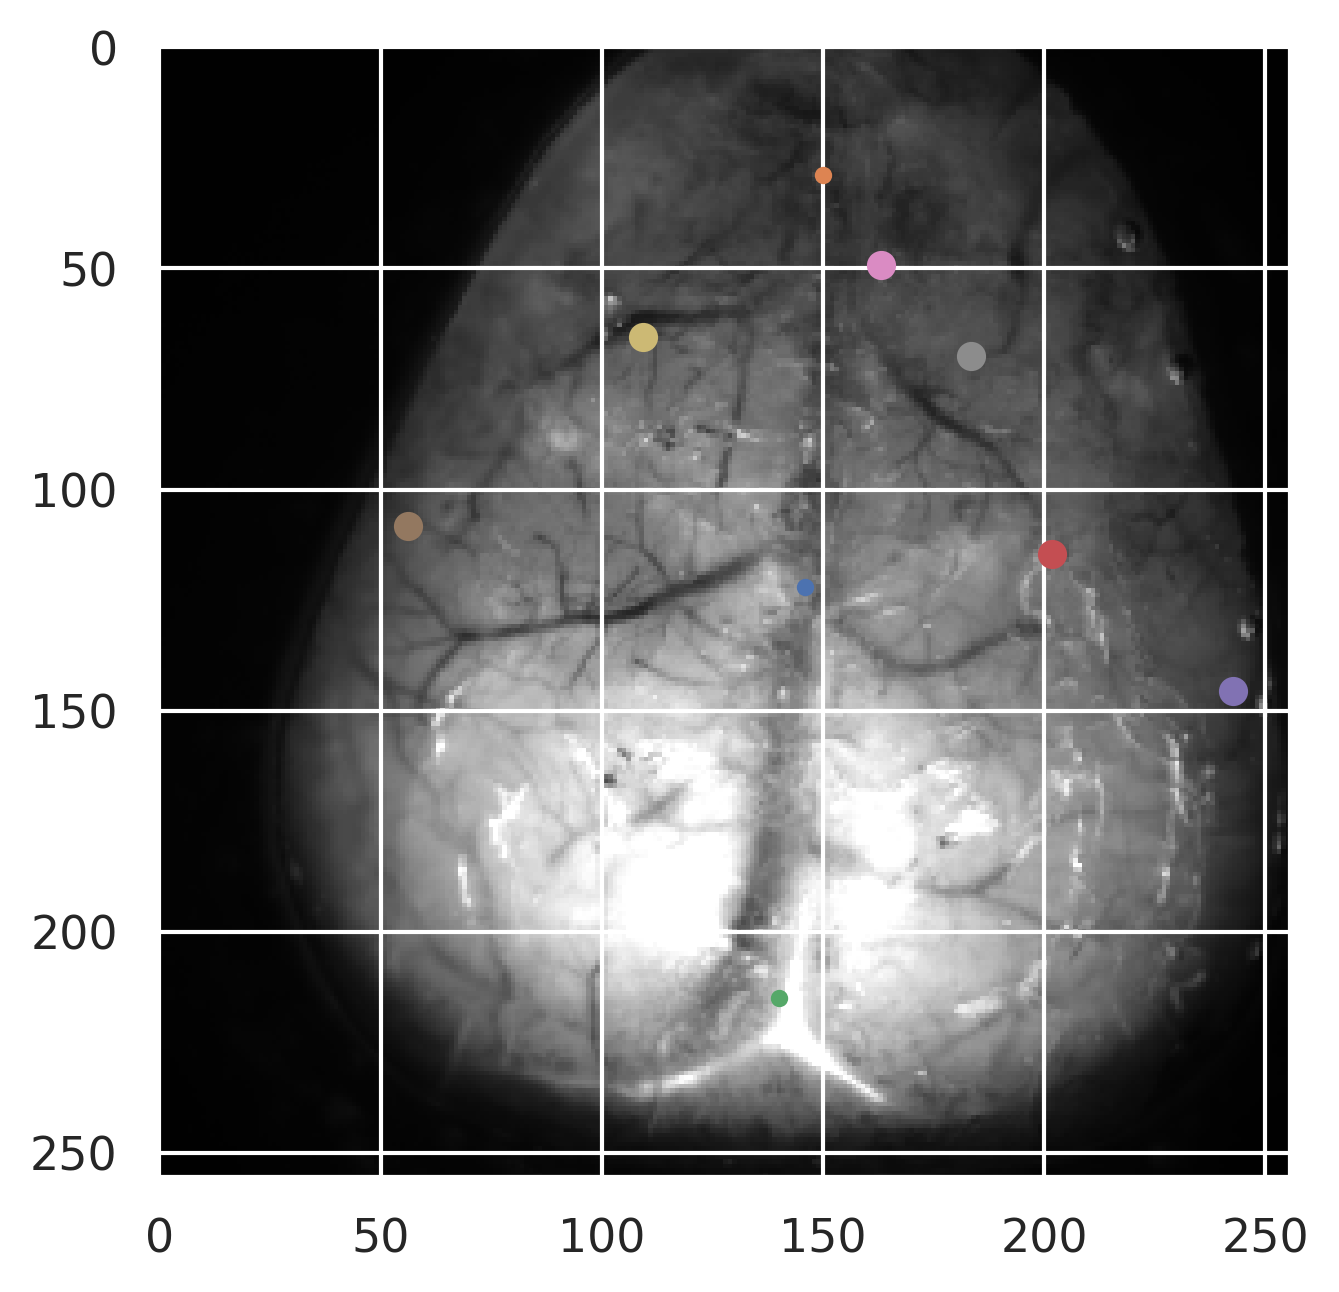

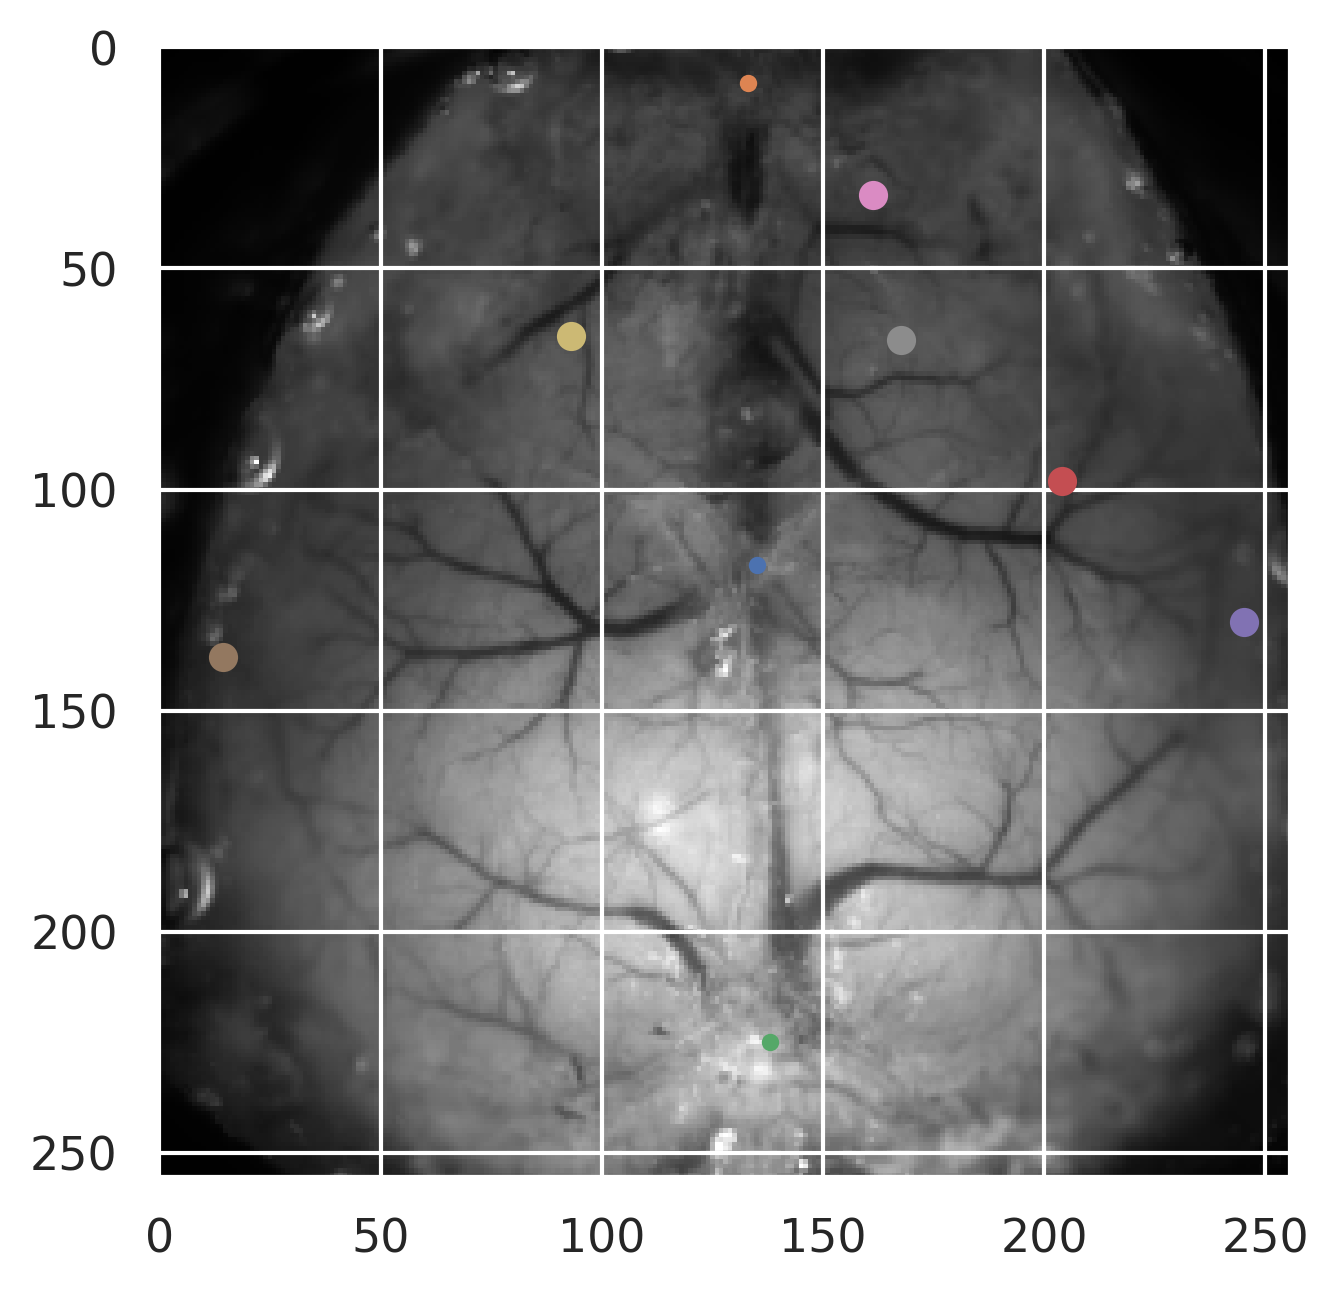

In [70]:
all_coord = {}
all_images = {}
all_mask = {}
for mouse in ['cm241','cm125']:
    all_coord[mouse] = {}
    if mouse=='cm125':
        neural_root= str(STEPS / "step_1") + "/"
        config_root = str(STEPS / "step_0") + "/"
        filename = neural_root+mouse+'/1/*runB*mat'
    elif mouse=='cm229':
        neural_root = str(STEPS / "step_1") + "/"
        config_root = str(STEPS / "step_0") + "/"
        filename = neural_root+mouse+'/2/*runB*mat'
    elif mouse=='cm193':
        config_root =  prefix+'users/wx2203/new_analysis_locker/data-locker/analysis/step_0/'
        neural_root = '/home/wx2203/hillman_servers/temp/hillman_servers/chronos/1/WFOM_DATA_ANALYSIS/dexmedetomidine/analysis/step_1/'
        filename = neural_root+mouse+'/4/*runB*full*mat'
    elif mouse=='cm216':
        neural_root = str(STEPS / "step_1") + "/"
        config_root = str(STEPS / "step_0") + "/"
        filename = neural_root+mouse+'/2/*runD*mat' # cm216_2_runD
    elif mouse=='cm265':
        neural_root = str(STEPS / "step_1") + "/"
        config_root = str(STEPS / "step_0/cm265") + "/"
        filename = neural_root+mouse+'/2/*runC*mat' # cm265_2_runC 
    elif mouse in ['cm241','cm242']:
        neural_root = str(STEPS / "step_1") + "/"
        config_root = str(STEPS / "step_0") + "/"
        filename = neural_root+mouse+'/8/*runB*_temp.mat' # cm241/2_8_runB
        
    fname = [f for f in glob.glob(filename, recursive=True)][0]

    with h5py.File(fname, "r") as f_H:
        m = f_H['m']
        C = np.array(f_H['C']['green'])
        S = np.array(f_H['S']['green'])[:2,:]
        # cut [-60,60] frames slice
        mask = np.array(f_H['mask'])
        all_mask[mouse]=mask.transpose()
        # nanidx = np.squeeze(~np.isnan(mask.reshape((1,-1))))
        nanidx = np.squeeze(m['nanidx'])==1
        CS = np.dot(S,C).transpose()
        lime = CS
        lime = lime.reshape((256,256,-1)).transpose((1,0,2))
    
    plt.figure(figsize=(5,5),dpi=300)
    plt.imshow(lime[:,:,0],cmap='gray',vmin=50,vmax=30000)
    # plt.imshow(lime[:,:,0],cmap='gray',vmin=200,vmax=5500)
    all_images[mouse]=lime[:,:,0]
  
    if mouse =='cm125':
        all_coord[mouse]['bregma']=np.array([135,117])
        all_coord[mouse]['al']=np.array([133,8])   
        all_coord[mouse]['back']=np.array([138,225]) 
        plt.scatter(all_coord[mouse]['bregma'][0],all_coord[mouse]['bregma'][1],s=10) #bregma location
        plt.scatter(all_coord[mouse]['al'][0],all_coord[mouse]['al'][1],s=10) # anterior landmark
        plt.scatter(all_coord[mouse]['back'][0],all_coord[mouse]['back'][1],s=10) # anterior landmark

    if mouse == 'cm241':
        all_coord[mouse]['bregma']=np.array([146,122])
        all_coord[mouse]['al']=np.array([150,29])   
        all_coord[mouse]['back']=np.array([140,215]) 
        plt.scatter(all_coord[mouse]['bregma'][0],all_coord[mouse]['bregma'][1],s=10) #bregma location
        plt.scatter(all_coord[mouse]['al'][0],all_coord[mouse]['al'][1],s=10) # anterior landmark
        plt.scatter(all_coord[mouse]['back'][0],all_coord[mouse]['back'][1],s=10) # anterior landmark

    # plt.scatter(184,28,s=1)
    # pixels_per_mm = scipy.spatial.distance.euclidean(np.array([155,28]), np.array([184,28]))
    # print('pixels_per_mm ',pixels_per_mm)
    
    
    with h5py.File(config_root+'idx_sorted_500_{}.mat'.format(mouse),'r') as f_idx:

        IDX_sorted = np.array(f_idx['IDX_sorted']).T
        IDX_sorted = IDX_sorted.astype(float)
        IDX_sorted[IDX_sorted==0]='nan'
        num_regions = int(np.nanmax(IDX_sorted.reshape((-1,1))))
        props = regionprops(IDX_sorted.astype(int))
        node_coords = [props[i].centroid for i in range(len(props))]
        node_coords = np.asarray(node_coords, dtype=np.float32)

    fetch_path=str(PREPARES / "sensory-boop-test") + "/"
    if mouse =='cm241':
        sensory_ind = load_pickle(fetch_path+'brightest_ind_'+mouse)
    else:
        sensory_ind = load_pickle(fetch_path+'inferred_brightest_ind_'+mouse)
        
# #     if mouse == 'cm229':
# #         sensory_ind['left_mouth']=15
# #         sensory_ind['right_mouth']=sensory_ind['mouth']
        
    if mouse in ['cm125','cm193','cm216']:
        fetch_path=str(PREPARES / "heterogeneity") + "/"
        extra_extra_ind = load_pickle(fetch_path+'extra_extra_ind_'+mouse)
        sensory_ind['right_mouth']=extra_extra_ind['right_mouth_sensory']
        sensory_ind['left_mouth'] = sensory_ind['mouth']
    elif mouse in ['cm265','cm241']:
        fetch_path=str(PREPARES / "heterogeneity") + "/"
        extra_extra_ind = load_pickle(fetch_path+'extra_extra_ind_'+mouse)
        sensory_ind['left_mouth']=extra_extra_ind['left_mouth_sensory']
        sensory_ind['right_mouth'] = sensory_ind['mouth']
        
    # for key in [ 'LFP','RFP','left_mouth','right_mouth']:
    #     ind = sensory_ind[key]
    #     all_coord[mouse][key+'-sensory'] = np.array([node_coords[ind,1],node_coords[ind,0]])
    #     plt.scatter(node_coords[ind,1],node_coords[ind,0])
    # !!!!!!!!!!!!!!WATCH OUT only for cm241
    for key in [ 'LFP','left_mouth','right_mouth']:
        ind = sensory_ind[key]
        all_coord[mouse][key+'-sensory'] = np.array([node_coords[ind,1],node_coords[ind,0]])
        plt.scatter(node_coords[ind,1],node_coords[ind,0])        
        
    fetch_path=str(PREPARES / "heterogeneity") + "/"
    motor_ind = load_pickle(fetch_path+'brightest_frontline_ind-'+mouse)
    if mouse in ['cm125','cm193','cm216']:
        extra_extra_ind = load_pickle(fetch_path+'extra_extra_ind_'+mouse)
        motor_ind['right_mouth']=extra_extra_ind['right_mouth_motor']
        motor_ind['left_mouth']=motor_ind['mouth']
    elif mouse in ['cm265','cm241']:
        extra_extra_ind = load_pickle(fetch_path+'extra_extra_ind_'+mouse)
        motor_ind['left_mouth']=extra_extra_ind['left_mouth_motor']
        motor_ind['right_mouth']=motor_ind['mouth']  
        
# # #     elif mouse =='cm229':
# # #         motor_ind['left_mouth']=127
# # #         motor_ind['right_mouth']=motor_ind['mouth']

    # !!!!!!!!!!!!!!WATCH OUT only for cm241
    for key in [ 'LFP','left_mouth','right_mouth']:
        ind = motor_ind[key]
        all_coord[mouse][key+'-motor'] = np.array([node_coords[ind,1],node_coords[ind,0]])
        plt.scatter(node_coords[ind,1],node_coords[ind,0])        
    # else:       
    #     for key in [ 'LFP','RFP','left_mouth','right_mouth']:
    #         ind = motor_ind[key]
    #         all_coord[mouse][key+'-motor'] = np.array([node_coords[ind,1],node_coords[ind,0]])
    #         plt.scatter(node_coords[ind,1],node_coords[ind,0])


https://stackoverflow.com/questions/25205635/how-to-register-face-by-landmark-points


https://stackoverflow.com/questions/18925181/procrustes-analysis-with-numpy

In [66]:
all_coord

{'cm241': {'bregma': array([146, 122]),
  'al': array([150,  29]),
  'back': array([143, 210]),
  'LFP-sensory': array([201.82222, 114.60741], dtype=float32),
  'left_mouth-sensory': array([242.73738, 145.65657], dtype=float32),
  'right_mouth-sensory': array([ 56.225, 108.25 ], dtype=float32),
  'LFP-motor': array([163.      ,  49.182926], dtype=float32),
  'left_mouth-motor': array([183.475,  69.8  ], dtype=float32),
  'right_mouth-motor': array([109.29592,  65.5102 ], dtype=float32)},
 'cm125': {'bregma': array([135, 117]),
  'al': array([133,   8]),
  'back': array([138, 225]),
  'LFP-sensory': array([204.1017 ,  98.11017], dtype=float32),
  'left_mouth-sensory': array([245.14764, 130.00671], dtype=float32),
  'right_mouth-sensory': array([ 14.348314, 137.89888 ], dtype=float32),
  'LFP-motor': array([161.35538 ,  33.363636], dtype=float32),
  'left_mouth-motor': array([167.57246 ,  66.195656], dtype=float32),
  'right_mouth-motor': array([92.93, 65.4 ], dtype=float32)}}

In [71]:
cm241_pts = np.asarray([item for key,item in all_coord['cm241'].items()])
cm125_pts = np.asarray([item for key,item in all_coord['cm125'].items()])


In [72]:
target_X_img = all_mask['cm125']
input_Y_img = all_mask['cm241']


import cv2
# Calculate transform via procrustes...
d,Z_pts,Tform = procrustes(cm125_pts,cm241_pts)
# Build and apply transform matrix...
# Note: for affine need 2x3 (a,b,c,d,e,f) form
R = np.eye(3)
R[0:2,0:2] = Tform['rotation']
S = np.eye(3) * Tform['scale'] 
S[2,2] = 1
t = np.eye(3)
t[0:2,2] = Tform['translation']
M = np.dot(np.dot(R,S),t.T).T
tr_Y_img = cv2.warpAffine(input_Y_img,M[0:2,:],(256,256))


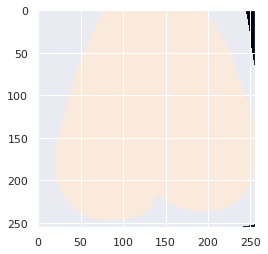

In [25]:
plt.imshow(tr_Y_img)

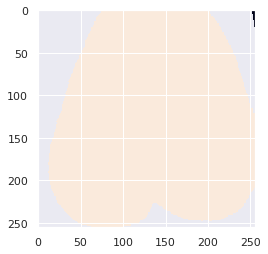

In [73]:
plt.imshow(tr_Y_img)

In [74]:
save_path = str(PREPARES / "registration") + "/"
dict_transform=load_model(save_path+'dict_transform')

In [75]:
dict_transform

{'cm229': array([[  1.07153532,   0.0600345 , -26.61299121],
        [ -0.0600345 ,   1.07153532,  -7.28183878],
        [  0.        ,   0.        ,   1.        ]]),
 'cm126': array([[  1.02201229,   0.08080067, -15.18793684],
        [ -0.08080067,   1.02201229,  -1.68760166],
        [  0.        ,   0.        ,   1.        ]]),
 'cm128': array([[ 1.03276026, -0.01388981, -3.89922036],
        [ 0.01388981,  1.03276026,  5.78991428],
        [ 0.        ,  0.        ,  1.        ]]),
 'cm193': array([[ 1.00443769, -0.0210364 ,  9.14083031],
        [ 0.0210364 ,  1.00443769, -8.93072151],
        [ 0.        ,  0.        ,  1.        ]]),
 'cm216': array([[  1.09922656,   0.03128542, -20.45906951],
        [ -0.03128542,   1.09922656,   5.81332111],
        [  0.        ,   0.        ,   1.        ]]),
 'cm265': array([[ 9.98832484e-01, -9.12301658e-03, -5.73401025e+00],
        [ 9.12301658e-03,  9.98832484e-01, -1.20058916e+01],
        [ 0.00000000e+00,  0.00000000e+00,  1.000000

In [76]:
dict_transform['cm241']=M

In [77]:
dict_transform

{'cm229': array([[  1.07153532,   0.0600345 , -26.61299121],
        [ -0.0600345 ,   1.07153532,  -7.28183878],
        [  0.        ,   0.        ,   1.        ]]),
 'cm126': array([[  1.02201229,   0.08080067, -15.18793684],
        [ -0.08080067,   1.02201229,  -1.68760166],
        [  0.        ,   0.        ,   1.        ]]),
 'cm128': array([[ 1.03276026, -0.01388981, -3.89922036],
        [ 0.01388981,  1.03276026,  5.78991428],
        [ 0.        ,  0.        ,  1.        ]]),
 'cm193': array([[ 1.00443769, -0.0210364 ,  9.14083031],
        [ 0.0210364 ,  1.00443769, -8.93072151],
        [ 0.        ,  0.        ,  1.        ]]),
 'cm216': array([[  1.09922656,   0.03128542, -20.45906951],
        [ -0.03128542,   1.09922656,   5.81332111],
        [  0.        ,   0.        ,   1.        ]]),
 'cm265': array([[ 9.98832484e-01, -9.12301658e-03, -5.73401025e+00],
        [ 9.12301658e-03,  9.98832484e-01, -1.20058916e+01],
        [ 0.00000000e+00,  0.00000000e+00,  1.000000

In [78]:
save_path = str(PREPARES / "registration") + "/"
save_model(dict_transform,save_path+'dict_transform')


